# 06 · Baseline ML Model (Experiment A)
Goal: predict the real target `default_next_month` from **conventional features only** (no graph), and measure it properly.

* Features: credit limit + the 18 raw monthly values + the engineered features frozen in notebook 03. **No demographics** (checked separately as an ablation).
* Model: Random Forest with balanced class weights (22% defaults).
* Metrics: ROC-AUC, PR-AUC, precision, recall, F1, confusion matrix. Accuracy is shown only for reference; predicting "no default" for everyone already scores 78%.

**Setup.**

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
from credit_kg import config as C
import json, pickle
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from credit_kg import modeling as M

**Load the feature table and build the Experiment A matrices.** The helper refuses to build a matrix that contains the target, the split flag or any scenario column.

In [2]:
table = M.load_table()
X, y, Xt, yt, ids_tr, ids_te = M.matrices(table, "A")
print("train", X.shape, "test", Xt.shape, "| default rate train %.3f test %.3f" % (y.mean(), yt.mean()))
print("features:", list(X.columns))

train (24000, 37) test (6000, 37) | default rate train 0.221 test 0.221
features: ['credit_limit', 'status_m1', 'status_m2', 'status_m3', 'status_m4', 'status_m5', 'status_m6', 'bill_m1', 'bill_m2', 'bill_m3', 'bill_m4', 'bill_m5', 'bill_m6', 'pay_m1', 'pay_m2', 'pay_m3', 'pay_m4', 'pay_m5', 'pay_m6', 'util_avg', 'util_slope', 'high_util_months', 'inactive_flag', 'coverage_median', 'coverage_min', 'coverage_latest', 'weak_cov_months', 'full_pay_months', 'late_months', 'late_recent3', 'max_status', 'status_latest', 'paid_full_months', 'no_use_months', 'pay_median', 'pay_latest', 'zero_pay_months']


**Light tuning (training data only).** We try a few tree settings with 5-fold cross-validation and keep the best by ROC-AUC. The same settings will be reused for the graph-enhanced model, so the comparison stays fair.

In [3]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=C.SEED)
grid = []
for leaf in [1, 5, 10, 20, 50, 100, 200]:
    for mf in ["sqrt", 0.3]:
        rf = M.make_rf(leaf); rf.set_params(max_features=mf)
        s = cross_val_score(rf, X, y, cv=cv5, scoring="roc_auc")
        grid.append({"min_samples_leaf": leaf, "max_features": mf, "cv_roc_auc": s.mean(), "sd": s.std()})
grid = pd.DataFrame(grid).sort_values("cv_roc_auc", ascending=False)
best = grid.iloc[0]
params = {"min_samples_leaf": int(best.min_samples_leaf), "max_features": best.max_features}
json.dump(params, open(C.MODELS / "rf_params.json", "w"))
print("chosen:", params); grid.round(4)

chosen: {'min_samples_leaf': 50, 'max_features': 0.3}


,min_samples_leaf,max_features,cv_roc_auc,sd
9,50,0.3,0.7883,0.0065
11,100,0.3,0.7882,0.0063
8,50,sqrt,0.7877,0.0059
10,100,sqrt,0.7873,0.0056
13,200,0.3,0.7870,0.0059
6,20,sqrt,0.7860,0.0059
12,200,sqrt,0.7858,0.0059
7,20,0.3,0.7855,0.0064
4,10,sqrt,0.7830,0.0067
5,10,0.3,0.7825,0.0070


**Model factory** with the chosen settings, used for every experiment from here on.

In [4]:
def rf():
    m = M.make_rf(params["min_samples_leaf"]); m.set_params(max_features=params["max_features"]); return m

**Repeated cross-validation (5 folds × 5 repeats = 25 scores) on the training data**, for three feature sets:
* `A0_raw`: only credit limit + the 18 raw monthly columns;
* `A`: + engineered features (our baseline);
* `A_demo`: + demographics (ablation only).

The folds are identical for every feature set, so later we can compare fold by fold.

In [5]:
cv_results = {}
for name in ["A0_raw", "A", "A_demo"]:
    Xn = M.matrices(table, name)[0]
    cv_results[name] = M.repeated_cv(Xn, y, rf)
    cv_results[name].to_csv(C.TABLES / f"cv_folds_{name}.csv", index=False)
summary = pd.DataFrame({k: {"roc_auc_mean": v.roc_auc.mean(), "roc_auc_sd": v.roc_auc.std(), "pr_auc_mean": v.pr_auc.mean(), "pr_auc_sd": v.pr_auc.std()}
                        for k, v in cv_results.items()}).T
summary.round(4)

,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd
A0_raw,0.7845,0.0072,0.5555,0.0116
A,0.7880,0.0067,0.5612,0.0121
A_demo,0.7887,0.0068,0.5627,0.0120


**Does feature engineering help, fold by fold?** A − A0 on the same 25 folds. Also: do demographics add anything? (A_demo − A).

In [6]:
pd.DataFrame({
    "engineered vs raw (A - A0)": cv_results["A"].roc_auc - cv_results["A0_raw"].roc_auc,
    "demographics (A_demo - A)": cv_results["A_demo"].roc_auc - cv_results["A"].roc_auc,
}).describe().loc[["mean", "std", "min", "max"]].round(4)

,engineered vs raw (A - A0),demographics (A_demo - A)
mean,0.0035,0.0007
std,0.0016,0.0009
min,-0.0012,-0.0008
max,0.0062,0.0023


**Sanity check with a simple interpretable model.** Logistic regression on the same features. If it were far better or worse than the forest, something would be off.

In [7]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
s = cross_val_score(lr, X, y, cv=cv5, scoring="roc_auc")
print(f"logistic regression 5-fold ROC-AUC: {s.mean():.4f} ± {s.std():.4f}")

logistic regression 5-fold ROC-AUC: 0.7664 ± 0.0070


**Choose the decision threshold without touching the test set.** We get *out-of-fold* probabilities for every training customer, then pick the cut-off that gives the best F1. The test set is only used once, below.

In [8]:
oof = M.oof_proba(X, y, rf)
thr = M.best_f1_threshold(y, oof)
print(f"OOF ROC-AUC {M.evaluate(y, oof, thr)['roc_auc']:.4f} | best-F1 threshold = {thr:.3f}")

OOF ROC-AUC 0.7880 | best-F1 threshold = 0.522


**Final fit on all training customers and a single evaluation on the test set**, at the OOF-chosen threshold and, for reference, at 0.5.

In [9]:
model_A = rf().fit(X, y)
p_test = model_A.predict_proba(Xt)[:, 1]
res = pd.DataFrame({"OOF threshold": M.evaluate(yt, p_test, thr), "threshold 0.5": M.evaluate(yt, p_test, 0.5)})
print(f"always-'no default' accuracy would be {1 - yt.mean():.3f}")
res.round(4)

always-'no default' accuracy would be 0.779


,OOF threshold,threshold 0.5
threshold,0.5224,0.5000
roc_auc,0.7800,0.7800
pr_auc,0.5575,0.5575
precision,0.4975,0.4779
recall,0.5961,0.6119
f1,0.5423,0.5367
accuracy,0.7775,0.7663
tn,3874.0000,3786.0000
fp,799.0000,887.0000
fn,536.0000,515.0000


**Confusion matrix (test, OOF threshold).** Top-right = false alarms, bottom-left = missed defaulters.

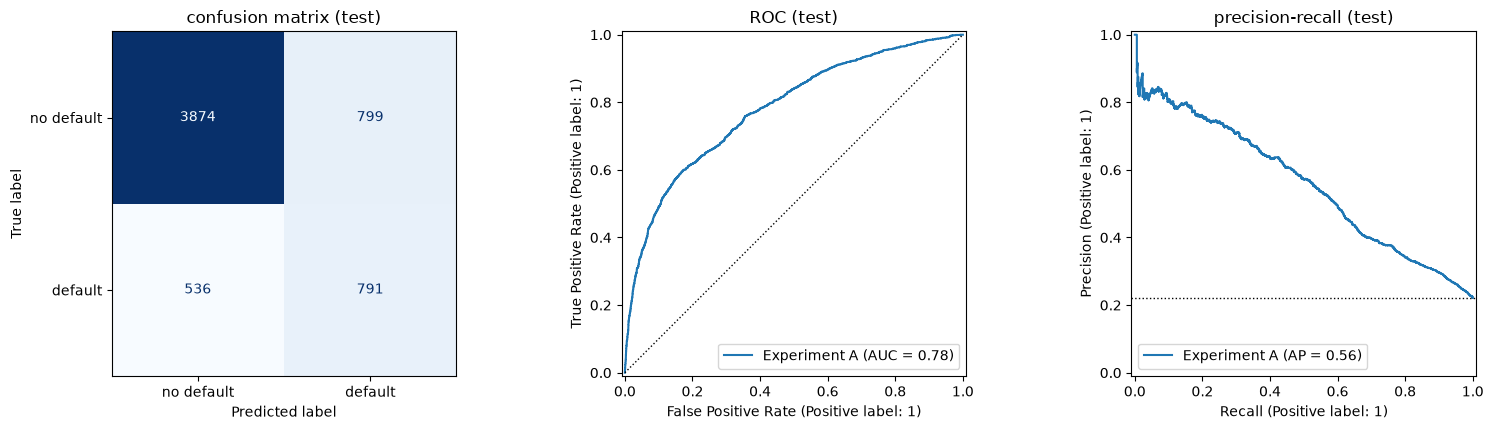

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ConfusionMatrixDisplay.from_predictions(yt, (p_test >= thr).astype(int), display_labels=["no default", "default"], ax=ax[0], colorbar=False, cmap="Blues")
RocCurveDisplay.from_predictions(yt, p_test, ax=ax[1], name="Experiment A"); ax[1].plot([0, 1], [0, 1], "k:", lw=1)
PrecisionRecallDisplay.from_predictions(yt, p_test, ax=ax[2], name="Experiment A"); ax[2].axhline(yt.mean(), color="k", ls=":", lw=1)
ax[0].set_title("confusion matrix (test)"); ax[1].set_title("ROC (test)"); ax[2].set_title("precision-recall (test)")
fig.tight_layout(); fig.savefig(C.FIGURES / "model_A_test.png", dpi=120)

**Are the probabilities calibrated?** Balanced class weights push the forest's scores upward, so a score of 0.6 does *not* mean a 60% chance. We will calibrate before using probabilities in the credit-increase scenario (notebook 07).

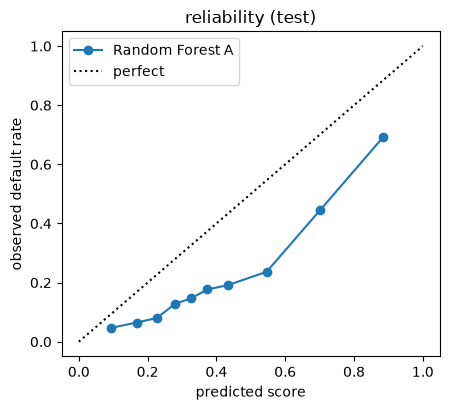

In [11]:
frac, mean_pred = calibration_curve(yt, p_test, n_bins=10, strategy="quantile")
plt.figure(figsize=(4.6, 4.2)); plt.plot(mean_pred, frac, "o-", label="Random Forest A"); plt.plot([0, 1], [0, 1], "k:", label="perfect")
plt.xlabel("predicted score"); plt.ylabel("observed default rate"); plt.legend(); plt.title("reliability (test)"); plt.tight_layout()
plt.savefig(C.FIGURES / "model_A_reliability.png", dpi=120)

**Which features does the model rely on?** Permutation importance on the test set: how much ROC-AUC drops when one feature is randomly shuffled. (More trustworthy than the forest's built-in importance.)

In [12]:
pi = permutation_importance(model_A, Xt, yt, scoring="roc_auc", n_repeats=5, random_state=C.SEED, n_jobs=-1)
imp = pd.DataFrame({"auc_drop": pi.importances_mean, "sd": pi.importances_std}, index=Xt.columns).sort_values("auc_drop", ascending=False)
imp.to_csv(C.TABLES / "importance_A.csv"); imp.head(15).round(4)

,auc_drop,sd
late_months,0.0059,0.0021
status_latest,0.0050,0.0012
bill_m6,0.0048,0.0008
util_avg,0.0040,0.0014
status_m6,0.0034,0.0010
max_status,0.0030,0.0011
late_recent3,0.0029,0.0014
credit_limit,0.0029,0.0011
high_util_months,0.0021,0.0006
util_slope,0.0020,0.0004


**Save** the model, predictions, threshold and metrics for notebook 07.

In [13]:
pickle.dump(model_A, open(C.MODELS / "model_A.pkl", "wb"))
pd.DataFrame({"customer_id": ids_tr, "oof_A": oof}).to_parquet(C.MODELS / "oof_A.parquet", index=False)
pd.DataFrame({"customer_id": ids_te, "p_A": p_test}).to_parquet(C.MODELS / "test_pred_A.parquet", index=False)
json.dump({"threshold": thr, "test": M.evaluate(yt, p_test, thr), "cv": summary.loc["A"].to_dict(), "features": list(X.columns)},
          open(C.MODELS / "model_A_meta.json", "w"), indent=2, default=float)
print("saved")

saved


### Takeaways
Numbers are in the tables above. In words:
* The baseline ranks defaulters reasonably well (ROC-AUC around 0.78), close to what this dataset usually allows.
* At the F1-optimal threshold it catches over half of the defaulters, and roughly half of its alarms are real defaults. Accuracy is misleading here.
* Engineered features add little over the raw monthly columns, and demographics add essentially nothing. That supports leaving demographics out.
* The most important inputs are the number of late months, the latest repayment status, the latest bill and average utilization. That matches the EDA and pattern validation.
* Logistic regression is a little weaker (~0.77), a sensible gap that suggests some non-linear effects (for example the U-shaped utilization).
* The raw probabilities are not calibrated. Notebook 07 calibrates them before they feed the scenario score.